## Deep Neural Networks(DNN)

In [1]:
import numpy as np
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
import tensorflow as tf
from typing import List
import matplotlib.pyplot as plt
# from tensorflow.keras.utils import to_categorical
# from tensorflow.keras.layers import Normalization 

#### 8.5. 과잉 적합과 과소 적합

- **영화 리뷰를 분류하는 문제**
  - IMDB 사이트의 영화리뷰 게시판 속 리뷰가 긍정적인지 부정적인지 파악하는 신경망
- 가중치 규제하는 문제, L1 or L2 
  - $Loss = Cost + \lambda \Sigma_{|W|}$
  - $Loss = Cost + \lambda \Sigma_{W^2}$
- Drop Out, 몇 개의 노드들을 학습 과정에서 랜덤하게 제외하는 것

In [2]:
(train_data, train_labels), (test_data, test_labels) = tf.keras.datasets.imdb.load_data(num_words = 1000)
# Downloading data from https://storage.googleapis.com/tensorflow/tf-keras-datasets/imdb.npz
# 17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step

In [3]:
type(train_data), type(train_labels), type(test_data), type(test_labels)

(numpy.ndarray, numpy.ndarray, numpy.ndarray, numpy.ndarray)

In [4]:
class MLPClassifier:
    """다층 퍼셉트론 신경망 학습 클래스"""

    def __init__(self,loss_function, unit = 16, learning_rate = 0.01,                
                 regularization = None, regularization_rate = 0.001):
        """모델과 활성화 함수, 컴파일 단 정의 및 초기화 메서드"""
        # None은 규제 없음, "l1"과 "l2"는 각 가중치 규제를 적용합니다.
        if regularization is None:
            kernel_regularizer = None
        elif regularization == "l1":
            kernel_regularizer = tf.keras.regularizers.l1(regularization_rate)
        # Loss_1 = Cost + \lambda \Sigma_{|W|}
        elif regularization == "l2":
            kernel_regularizer = tf.keras.regularizers.l2(regularization_rate)
        # Loss_2 = Cost + \lambda \Sigma_{W^2}
        else:
            raise ValueError("regularization은 None, 'l1', 'l2' 중 하나를 선택합니다.")

        self.regularization = regularization

        self.model = tf.keras.Sequential(
            [
                tf.keras.layers.Dense(
                    unit,
                    activation = "relu",
                    input_shape = (1000, ),
                    kernel_regularizer = kernel_regularizer
                ),
                tf.keras.layers.Dense(
                    unit,
                    activation = "relu",
                    kernel_regularizer = kernel_regularizer
                ),
                tf.keras.layers.Dense(1, activation = "sigmoid")
            ]
        )
        # self.model.add(tf.keras.layers.Dropout(0.5))
        # 몇 개의 노드들을 학습 과정에서 랜덤하게 제외
        
        self.model.compile(
            optimizer = "adam",
            loss = loss_function,
            # "binary_crossentropy", "sparse_categorical_crossentropy"
            metrics = ["accuracy"]
        )
        self.reference: List = []


    @staticmethod
    def one_hot_sequences(sequences, dimension = 1000):
        """리뷰의 단어 인덱스를 길이 dimension의 multi-hot 배열로 변환하는 메서드"""
        results = np.zeros((len(sequences), dimension), dtype = np.float32)
        for i, word_index in enumerate(sequences):
            # 동일 단어가 여러 번 있어도 해당 위치에는 1을 기록
            valid_indices = np.asarray(word_index, dtype = np.int64)
            valid_indices = valid_indices[(valid_indices >= 0) & (valid_indices < dimension)]
            results[i, valid_indices] = 1.
        return results


    def train(self, inputs: np.ndarray, labels: np.ndarray,
              validation_data: np.ndarray = None, validation_labels: np.ndarray = None,
              epochs = 20, batch_size = 512, validation_split = 0.2):
        # validation data가 따로 전달되면 사용하고, 아니면 훈련 데이터 일부를 검증에 사용
        fit_options = {
            "epochs": epochs, # 입력값 없을 경우 기본값 20
            "batch_size": batch_size, # 입력값 없을 경우 기본값 512
            "verbose": 2
        }
        if validation_data is not None and validation_labels is not None:
            fit_options["validation_data"] = (validation_data, validation_labels)
        else:
            fit_options["validation_split"] = validation_split

        self.reference = self.model.fit(inputs, labels, **fit_options)
        return self.reference
    

    def predict(self, train_inputs: np.ndarray, thresholds = 0.5):
        probabilities = self.model.predict(
            train_inputs, verbose = 0
        ) # 모델의 시그모이드 출력 확률을 계산합니다.
        return (probabilities >= thresholds).astype(int) # 임계값 기준으로 0/1 분류
        # TypeError: Expected int32 passed to parameter 'size' of op 'Slice', got [5.0] of type 'list' instead. Error: Expected int32, but got 5.0 of type 'float'.

    def evaluate(self, test_inputs: np.ndarray, test_labels: np.ndarray):
        """테스트 데이터의 손실과 정확도를 반환하는 메서드"""
        return self.model.evaluate(test_inputs, test_labels, verbose = 0)

In [5]:
# 리뷰 시퀀스를 모델이 사용할 수 있는 고정 길이 벡터로 변환
# 이 변환은 훈련 데이터와 테스트 데이터 모두에 동일하게 적용
train_data = MLPClassifier.one_hot_sequences(train_data, dimension = 1000)
test_data = MLPClassifier.one_hot_sequences(test_data, dimension = 1000)

print("훈련 입력 형태:", train_data.shape)
print("테스트 입력 형태:", test_data.shape)

훈련 입력 형태: (25000, 1000)
테스트 입력 형태: (25000, 1000)


In [7]:
# 규제 선택: None(규제 없음), "l1", "l2"
regularization = None
# True이면 세 가지 설정을 모두 학습해 비교
compare_regularization = True
regularization_options = (None, "l1", "l2") if compare_regularization else (regularization,)

classifiers = {}
references = {}
for regularization_option in regularization_options:
    model_name = "none" if regularization_option is None else regularization_option
    ReviewClassifier = MLPClassifier(
        loss_function = "binary_crossentropy",
        unit = 16,
        learning_rate = 0.01,
        regularization = regularization_option,
        regularization_rate = 0.001
    )
    references[model_name] = ReviewClassifier.train(
        train_data,
        train_labels,
        epochs = 20,
        batch_size = 512,
        validation_split = 0.2
    )
    classifiers[model_name] = ReviewClassifier

# 예측할 때는 입력 데이터만 전달합니다. 레이블과 테스트 데이터를 predict에 넘기지 않음
print(classifiers["none"].predict(test_data[:5]).reshape(-1))

Epoch 1/20


/opt/homebrew/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


40/40 - 1s - 25ms/step - accuracy: 0.6955 - loss: 0.5998 - val_accuracy: 0.8094 - val_loss: 0.4564
Epoch 2/20
40/40 - 0s - 2ms/step - accuracy: 0.8370 - loss: 0.3913 - val_accuracy: 0.8530 - val_loss: 0.3554
Epoch 3/20
40/40 - 0s - 2ms/step - accuracy: 0.8615 - loss: 0.3289 - val_accuracy: 0.8610 - val_loss: 0.3349
Epoch 4/20
40/40 - 0s - 2ms/step - accuracy: 0.8713 - loss: 0.3082 - val_accuracy: 0.8634 - val_loss: 0.3307
Epoch 5/20
40/40 - 0s - 2ms/step - accuracy: 0.8756 - loss: 0.3036 - val_accuracy: 0.8638 - val_loss: 0.3312
Epoch 6/20
40/40 - 0s - 2ms/step - accuracy: 0.8773 - loss: 0.2975 - val_accuracy: 0.8614 - val_loss: 0.3342
Epoch 7/20
40/40 - 0s - 2ms/step - accuracy: 0.8793 - loss: 0.2909 - val_accuracy: 0.8648 - val_loss: 0.3323
Epoch 8/20
40/40 - 0s - 2ms/step - accuracy: 0.8814 - loss: 0.2866 - val_accuracy: 0.8618 - val_loss: 0.3389
Epoch 9/20
40/40 - 0s - 2ms/step - accuracy: 0.8819 - loss: 0.2835 - val_accuracy: 0.8622 - val_loss: 0.3324
Epoch 10/20
40/40 - 0s - 2ms/

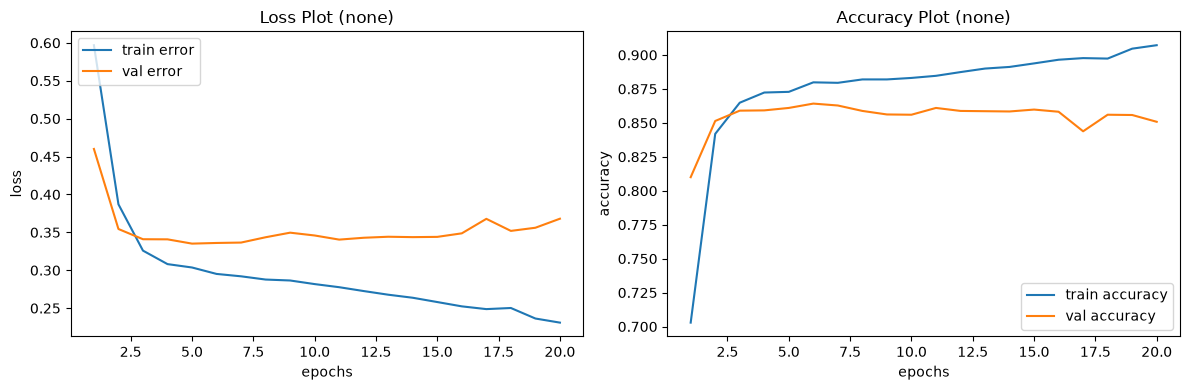

none: test loss=0.3689, test accuracy=0.8475


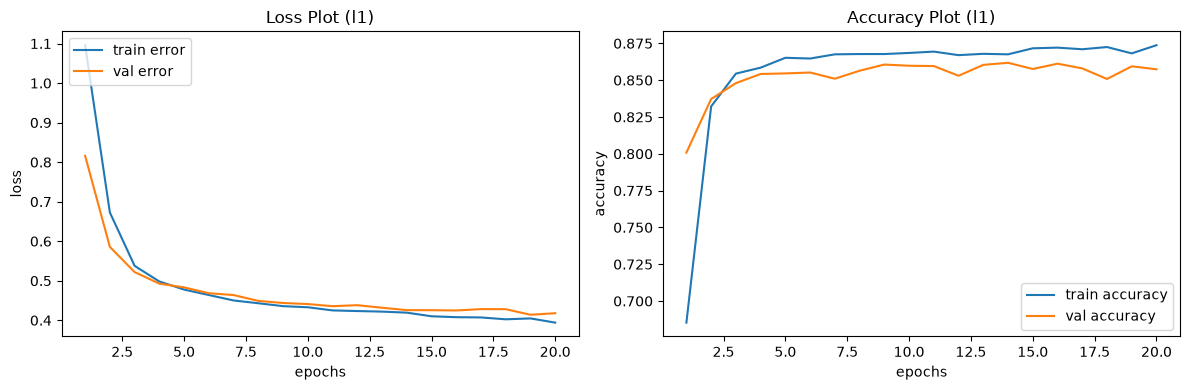

l1: test loss=0.4211, test accuracy=0.8568


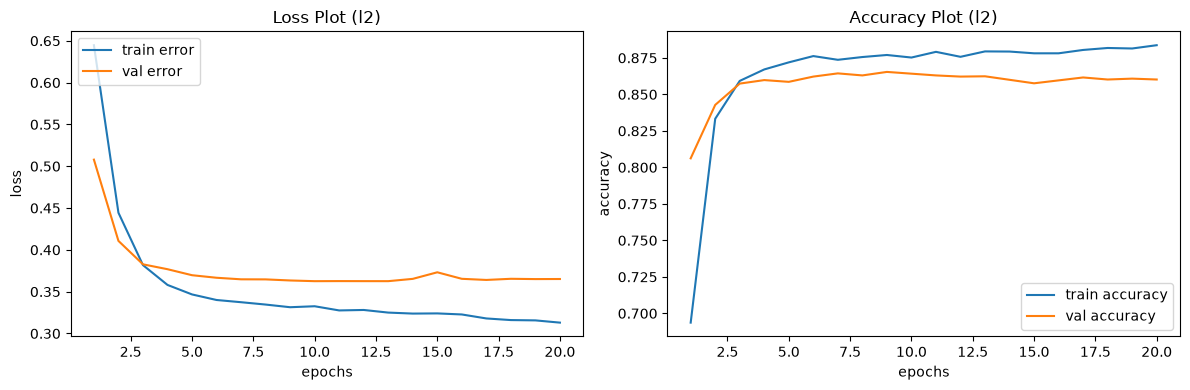

l2: test loss=0.3698, test accuracy=0.8553


In [ ]:
# 훈련 데이터의 손실값과 검증 데이터의 손실값을 그래프에 출력
for model_name, history in references.items():
    history_dict = history.history

    loss_values = history_dict['loss']
    val_loss_values = history_dict['val_loss']
    acc = history_dict['accuracy'] # 정확도
    val_acc = history_dict['val_accuracy']

    epochs = range(1, len(acc) + 1) # 에포크 수

    fig, axes = plt.subplots(1, 2, figsize = (12, 4))

    # 훈련 데이터 손실값과 검증 데이터 손실값
    axes[0].plot(epochs, loss_values, label = 'train error')
    axes[0].plot(epochs, val_loss_values, label = 'val error')
    axes[0].set_title(f'Loss Plot ({model_name})')
    axes[0].set_ylabel('loss')
    axes[0].set_xlabel('epochs')
    axes[0].legend(loc = 'upper left')

    # 훈련 데이터 정확도와 검증 데이터 정확도
    axes[1].plot(epochs, acc, label = 'train accuracy')
    axes[1].plot(epochs, val_acc, label = 'val accuracy')
    axes[1].set_title(f'Accuracy Plot ({model_name})')
    axes[1].set_ylabel('accuracy')
    axes[1].set_xlabel('epochs')
    axes[1].legend(loc = 'lower right')

    plt.tight_layout()
    plt.show()

    test_loss, test_accuracy = classifiers[model_name].evaluate(test_data, test_labels)
    print(f"{model_name}: test loss={test_loss:.4f}, test accuracy={test_accuracy:.4f}")

#### 8.6. 드롭아웃과 앙상블

- Drop Out, 몇 개의 노드들을 학습 과정에서 랜덤하게 제외하는 것
- Ensemble, 동일한 딥러닝 신경망 N개를 독립적으로 학습시킨 후에 마지막으로 합치는 것
- **MNIST 필기체 숫자 인식하는 문제**

In [9]:
mnist = tf.keras.datasets.mnist
(X_train, y_train), (X_test, y_test) = mnist.load_data()
X_train, X_test = X_train / 255.0, X_test / 255.0

# 규제 선택: None(규제 없음), "l1", "l2"
regularization = None

# True이면 세 가지 설정을 모두 학습해 비교
compare_regularization = True
regularization_options = (None, "l1", "l2") if compare_regularization else (regularization,)

classifiers = {}
references = {}
for regularization_option in regularization_options:
    model_name = "none" if regularization_option is None else regularization_option
    MNISTClassifier = MLPClassifier(
        loss_function = "sparse_categorical_crossentropy",
        unit = 16,
        learning_rate = 0.01,
        regularization = regularization_option,
        regularization_rate = 0.001
    )
    references[model_name] = MNISTClassifier.train(
        train_data,
        train_labels,
        epochs = 20,
        batch_size = 512,
        validation_split = 0.2
    )
    classifiers[model_name] = MNISTClassifier

# 예측할 때는 입력 데이터만 전달합니다. 레이블과 테스트 데이터를 predict에 넘기지 않음
print(classifiers["none"].predict(test_data[:5]).reshape(-1))

Epoch 1/20


W0000 00:00:1794916242.062637 1523754 op_kernel.cc:1858] OP_REQUIRES failed at sparse_xent_op.cc:103 : INVALID_ARGUMENT: Received a label value of 1 which is outside the valid range of [0, 1).  Label values: 1 0 0 0 0 1 1 1 1 1 0 1 1 1 1 1 0 1 0 1 0 0 0 1 1 0 0 0 0 1 0 1 1 0 0 1 0 0 0 1 1 0 0 0 1 0 0 0 1 0 0 0 0 1 1 1 0 0 0 1 1 1 0 0 1 0 0 0 0 0 0 1 1 1 0 0 0 0 1 0 0 1 0 1 1 1 0 0 0 1 0 0 1 0 1 0 0 0 0 0 1 0 0 1 0 1 0 0 0 0 0 1 0 1 0 0 0 0 0 0 1 1 1 1 0 1 0 1 1 0 0 1 0 1 1 0 1 1 1 0 1 1 1 1 0 0 0 0 1 1 0 0 0 1 1 0 0 0 1 0 1 0 0 0 0 1 1 1 1 1 0 0 0 1 0 0 1 1 0 0 1 1 0 1 1 1 1 1 1 1 0 0 0 0 1 1 1 0 1 1 1 0 0 1 0 1 1 0 1 1 1 0 0 0 0 0 1 1 1 0 1 0 0 0 1 1 0 1 0 0 1 0 1 0 1 0 1 0 1 0 0 0 0 0 1 1 1 1 1 0 1 0 1 0 0 1 0 0 0 1 0 1 0 0 1 1 0 1 1 0 1 0 1 0 0 0 0 0 0 1 1 0 0 0 0 0 1 1 1 1 0 0 1 1 1 0 1 1 1 0 1 0 1 1 1 1 1 1 1 0 1 0 0 1 0 1 0 1 0 0 0 0 1 0 1 0 0 0 0 0 1 0 0 0 0 0 1 0 0 1 0 0 1 1 1 0 0 0 0 1 1 0 1 1 1 1 0 0 1 0 0 1 1 0 1 1 1 0 1 1 0 0 1 1 1 0 0 1 1 1 0 1 1 0 1 0 1 0 1 1 0 1 1 1 1 1 

InvalidArgumentError: Graph execution error:

Detected at node compile_loss/sparse_categorical_crossentropy/SparseSoftmaxCrossEntropyWithLogits/SparseSoftmaxCrossEntropyWithLogits defined at (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main

  File "<frozen runpy>", line 88, in _run_code

  File "/Users/ksydata/Library/Python/3.12/lib/python/site-packages/ipykernel_launcher.py", line 18, in <module>

  File "/Users/ksydata/Library/Python/3.12/lib/python/site-packages/traitlets/config/application.py", line 1080, in launch_instance

  File "/Users/ksydata/Library/Python/3.12/lib/python/site-packages/ipykernel/kernelapp.py", line 768, in start

  File "/Users/ksydata/Library/Python/3.12/lib/python/site-packages/tornado/platform/asyncio.py", line 203, in start

  File "/opt/homebrew/Cellar/python@3.12/3.12.16/Frameworks/Python.framework/Versions/3.12/lib/python3.12/asyncio/base_events.py", line 645, in run_forever

  File "/opt/homebrew/Cellar/python@3.12/3

---

#### 8.1. gradient 기울기 소실 문제
- 심층 신경망에서 gradient가 전달되다가 점차 0에 가까워짐
- 예를 들어, 시그모이드 활성화 함수 특성상 아주 큰 값이나 작은 값이 들어오면 미분값이 거의 0이 됌
- 이를 해결하기 위해 심층 신경망에서 ReLu함수를 활용
- @https://playground.tensorflow.org

#### 8.2. 손실함수 선택 문제와 softmax 활성화 함수

- softmax 함수 : $\frac{e^{2.0}}{e^{2.0}+e^{1.0}+e^{0.1}}$
  - 0일 확률 0.1, 1일 확률 0.7, 0일 확률 0.2
  - 큰 값은 더 커지고, 작은 값은 더 작아지는 특성
  - 정보이론에서의 불확실성 척도
  - 손실확률 분포 : Cross Entropy = $H(p, q) = -\Sigma_{x}p(x)log_{n}{q(x)}$
  
- maximum likelihood estimation : $p(d|x) = p(d=1|x)^{d} \cdots p(d=0|x)^{1-d}$
  - 주어진 데이터를 바르게 예측할 확률을 최대화한 것
  
- cross entropy loss [=negative log likelihood]
  - 다중 클래스 분류 문제에서 모델의 출력을 softmax 함수를 통해 확률값으로 변환 후, 실제 레이블과의 차이를 최소화하기 위해 사용
  - 곱셈을 반복하면 underflow가 생기므로 log로 변환
  - 이진 교차 엔트로피(BCE) 
  - categorical cross entropy

- cross entropy의 계산
  - 교차 엔트로피: 실제 정답 데이터의 확률 분포와 모델이 예측한 확률 분포(\(q_{i}\))가 얼마나 다른지(오차)를 측정하는 손실 함수
  - $E = -\sum_{i} t_{i} \log y_{i} \\$ ($t$: 목표 출력, $y$: 실제 출력, $\log$: 자연로그) 

    | 입력 샘플 | 실제 출력 1 | 실제 출력 2 | 실제 출력 3 | 목표 출력 1 | 목표 출력 2 | 목표 출력 3 |
    |:---:|:---:|:---:|:---:|:---:|:---:|:---:|
    | 샘플 #1 | 0.1 | 0.3 | 0.6 | 0 | 0 | 1 |
    | 샘플 #2 | 0.2 | 0.6 | 0.2 | 0 | 1 | 0 |
    | 샘플 #3 | 0.3 | 0.4 | 0.3 | 1 | 0 | 0 |

- 첫 번째 샘플의 교차 엔트로피
  - $-(\log(0.1)\cdot 0 + \log(0.3)\cdot 0 + \log(0.6)\cdot 1) = -(0 + 0 - 0.51) = 0.51$
- 두 번째 샘플의 교차 엔트로피
  - $-(\log(0.2)\cdot 0 + \log(0.6)\cdot 1 + \log(0.2)\cdot 0) = -(0 - 0.51 + 0) = 0.51
$
- 세 번째 샘플의 교차 엔트로피
  - $-(\log(0.3)\cdot 1 + \log(0.4)\cdot 0 + \log(0.3)\cdot 0) = -(-1.20 + 0 + 0) = 1.20$
- 3가지 샘플의 평균 교차 엔트로피 오류는
  - $\frac{0.51 + 0.51 + 1.20}{3} = 0.74$

#### 8.3. 가중치 초기화 문제

- breaking the symmetry
- 난수 가중치 초기값 : $var(W_{i}) = \frac{2}{N_{in} + N_{out}}$
- 범주형 변수 encoding (3) : integer encoding, one hot encoding, embedding

#### 8.4. 데이터 스케일링 방법

1. 정규화 (Min-Max Scaling)
   - 데이터를 $[0, 1]$ 범위로 변환
   - $x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$
2. 표준화 (Z-score Standardization)
   - 평균이 $0$, 표준편차가 $1$이 되도록 변환
   - $z = \frac{x - \mu}{\sigma}$

---